# <b>Table of Contents</b>

* [Introduction](#intro)
* [Baseline](#baseline)
* [Feature Engineering experiments](#features)
* [Models experiments](#models)
* [Results overview](#results)
* [Submission](#submission)
* [Conclusion](#conclusion)

<a id='intro'></a>
# Introduction

Second round against the Forest Cover Type Prediction competition.

This time I will be even more synthetic than usual, as most of my work is already explained on my first attempt: see https://www.kaggle.com/code/huberthamelin/forest-cover-type-prediction for more details.

The objective is clear : try to beat the first attempt results !

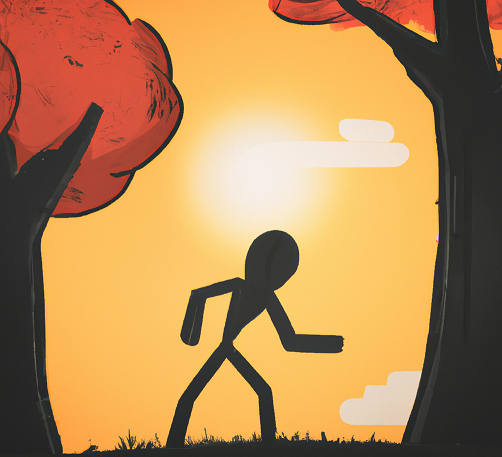

In order to achieve said objective, I will go deeper into feature engineering and model stacking.

In [ ]:
# Imports
import math
import pandas as pd
import numpy as np
import copy as cp
import seaborn as sns
from typing import Tuple
from statistics import mean
from matplotlib import pyplot as plt
from scipy.stats import norm
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from keras.layers import Embedding, Flatten, Dense, Input, BatchNormalization, LeakyReLU, Dropout
from keras.models import Sequential, Model
from keras.optimizers import adam_v2

In [ ]:
# Utils

def evaluate_model_on_dataset(model: object, X : np.array, y : np.array, sorted_labels : list, verbose: int=0):
    kfold = KFold(n_splits=10, random_state=42, shuffle=True)
    actual_classes, predicted_classes, _ = cross_val_predict(model, kfold, X, y)
    if verbose > 0:
        plot_confusion_matrix(actual_classes, predicted_classes, sorted_labels)
    accuracy = accuracy_score(actual_classes, predicted_classes)
    return accuracy

    
def cross_val_predict(model, kfold : KFold, X : np.array, y : np.array) -> Tuple[np.array, np.array, np.array]:
    model_ = cp.deepcopy(model)
    no_classes = len(np.unique(y))
    actual_classes = np.empty([0], dtype=int)
    predicted_classes = np.empty([0], dtype=int)
    predicted_proba = np.empty([0, no_classes]) 
    for train_ndx, test_ndx in kfold.split(X):
        train_X, train_y, test_X, test_y = X[train_ndx], y[train_ndx], X[test_ndx], y[test_ndx]
        actual_classes = np.append(actual_classes, test_y)
        model_.fit(train_X, train_y)
        predicted_classes = np.append(predicted_classes, model_.predict(test_X))
        try:
            predicted_proba = np.append(predicted_proba, model_.predict_proba(test_X), axis=0)
        except:
            predicted_proba = np.append(predicted_proba, np.zeros((len(test_X), no_classes), dtype=float), axis=0)
    return actual_classes, predicted_classes, predicted_proba


def plot_confusion_matrix(actual_classes : np.array, predicted_classes : np.array, sorted_labels : list):
    matrix = confusion_matrix(actual_classes, predicted_classes, labels=sorted_labels)
    plt.figure(figsize=(12.8,6))
    sns.heatmap(matrix, annot=True, xticklabels=sorted_labels, yticklabels=sorted_labels, cmap="Blues", fmt="g")
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix')
    plt.show()


results = {
    'model': [],
    'data': [],
    'accuracy': [],
    'seed': []
}


def add_result(model: str, data: str, accuracy: float, seed: int) -> None:
    results['model'].append(model)
    results['data'].append(data)
    results['accuracy'].append(accuracy)
    results['seed'].append(seed)


def plot_results() -> pd.DataFrame:
    return pd.DataFrame(results)


def get_two_classes_subset(X: pd.DataFrame, y: pd.DataFrame, class_1: int, class_2: int) -> tuple:
    indices = np.argwhere((y.to_numpy() == class_1) | (y.to_numpy() == class_2))
    X_sub = X.to_numpy()[indices].squeeze()
    y_sub = y.to_numpy()[indices]
    X_sub_df = pd.DataFrame(X_sub, columns=X.columns)
    y_sub_df = pd.DataFrame(y_sub)
    return X_sub_df, y_sub_df


def get_three_classes_subset(y: pd.DataFrame, class_1: int, class_2: int, substitute_class: int) -> pd.DataFrame:
    indices = np.argwhere((y.to_numpy() != class_1) & (y.to_numpy() != class_2))
    y_sub = y.copy()
    y_sub.to_numpy()[indices] = substitute_class
    y_sub_df = pd.DataFrame(y_sub)
    return y_sub_df

<a id='baseline'></a>
# Baseline

This was quite a surprise for me during the first attempt. Testing and validation scores were above 85%, but the submission score was only 77.9%. What did I do wrong ?

Well the problem was in my initial sets split. For the submission, there is a proportion of approximately 3% training data only. So if I want to have more realistic training and validation scores, I need to implement such a split, which I did. And the baseline is already much more coherent with what I now know about the competition scores.

In [ ]:
# Load data
train_dataframe = pd.read_csv("/kaggle/input/forest-cover-type-prediction/train.csv")
test_dataframe = pd.read_csv("/kaggle/input/forest-cover-type-prediction/test.csv")
partial_augmented_dataframe = pd.read_csv("/kaggle/input/forest-cover-type-augmented/partial_augmented_data.csv")
partial_augmented_dataframe_seed_42 = pd.read_csv("/kaggle/input/forest-cover-type-augmented/partial_augmented_data_seed_42.csv")
partial_augmented_dataframe_seed_73 = pd.read_csv("/kaggle/input/forest-cover-type-augmented/partial_augmented_data_seed_73.csv")
partial_augmented_dataframe_seed_31 = pd.read_csv("/kaggle/input/forest-cover-type-augmented/partial_augmented_data_seed_31.csv")
augmented_dataframe = pd.read_csv("/kaggle/input/forest-cover-type-augmented/augmented_data.csv")

X_all = train_dataframe.drop('Cover_Type', axis='columns')
y_all = train_dataframe['Cover_Type']

class_1 = 1
class_2 = 7
# sorted_labels = [class_1, class_2]
# X_1_2, y_1_2 = get_two_classes_subset(X_all, y_all, class_1, class_2)
# X_train_l, X_test, y_train_l, y_test = train_test_split(X_1_2, y_1_2, test_size=0.8, random_state=21)

sorted_labels = [1, 2, 3, 4, 5, 6, 7]
train_seed = 18
X_train_l, X_test, y_train_l, y_test = train_test_split(X_all, y_all, test_size=0.85, random_state=21)
X_train, X_val, y_train, y_val = train_test_split(X_train_l, y_train_l, test_size=0.25, random_state=train_seed)

N_ESTIMATORS = 64
MAX_DEPTH = 16

In [ ]:
# --- UTILS ---

def features_distribution(X: pd.DataFrame) -> None:
    fig, ((ax0, ax1), (ax2, ax3), (ax4, ax5), (ax6,ax7), (ax8, ax9)) = plt.subplots(5, 2, figsize=(30, 20))
    axs = [ax0, ax1, ax2, ax3, ax4, ax5, ax6,ax7, ax8, ax9]
    for feature, ax in zip(X.columns[1:11], axs):
        x = X[feature].to_numpy()
        ax.hist(x, bins=40)
        ax.set_title(feature)
    plt.show()
    

def continuous_feature_distribution(X: pd.DataFrame, y: pd.DataFrame, feature_name, class_1: int, class_2: int) -> None:
    # Get data according to class
    y_1 = []
    y_2 = []
    for val, label in zip(X[feature_name], y.to_numpy()):
        if label == class_1:
            y_1.append(val)
        elif label == class_2:
            y_2.append(val)
    
    # Fit a Normal distribution for each class
    mu_1, std_1 = norm.fit(y_1)
    mu_2, std_2 = norm.fit(y_2) 
    print("Fit Values for class 1: {:.2f} and {:.2f}".format(mu_1, std_1))
    print("Fit Values for class 2: {:.2f} and {:.2f}".format(mu_2, std_2))
    
    # Plot everything
    plt.figure(figsize=(20, 10))
    plt.hist(np.asarray(y_1), bins=100, label=class_1, color='blue', alpha=0.5, density=True)
    plt.hist(np.asarray(y_2), bins=100, label=class_2, color='orange', alpha=0.5, density=True)
    
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    p_1 = norm.pdf(x, mu_1, std_1)
    p_2 = norm.pdf(x, mu_2, std_2)
    plt.plot(x, p_1, color='blue', linewidth=1)
    plt.plot(x, p_2, color='orange', linewidth=1)
    
    plt.legend()
    plt.title(f'Normed {feature_name} distribution')
    plt.show()

    
def categorical_feature_distribution(X: pd.DataFrame, y: pd.DataFrame, feature_name: str, class_1: int, class_2: int) -> None:
    y_1 = []
    y_2 = []
    for col in X.columns:
        if feature_name in col:
            count_1 = 0
            count_2 = 0
            for val, label in zip(X[col], y.to_numpy()):
                if label == class_1:
                    count_1 += val
                elif label == class_2:
                    count_2 += val
            y_1.append(count_1)
            y_2.append(count_2)
            
    width = 0.25    
    plt.figure(figsize=(20, 10))
    x = np.arange(len(y_1)) + 1
    plt.bar(x, y_1, width, label=class_1)
    plt.bar(x + width, y_2, width, label=class_2)
    plt.legend()
    plt.title(f'{feature_name} distribution')
    plt.show()

In [ ]:
# --- UTILS ---

def get_features_without_variance(X: pd.DataFrame) -> list:
    # Searching for features with no variance within the dataset.
    statistical_analysis = X.describe()
    features_to_drop = []

    for feature in statistical_analysis.columns:
        if statistical_analysis._get_value('std', feature) == 0:
            features_to_drop.append(feature)
    
    return features_to_drop


def drop_features(X: pd.DataFrame, features: list, verbose: int = 0) -> pd.DataFrame:
    for feature in features:
        X = X.drop(feature, axis='columns')
        if verbose > 0:
            print(f'{feature} dropped')
    return X


def get_previous_features(X: pd.DataFrame) -> pd.DataFrame:
    new_X = X.copy()
    
    # Regarding Distances
    new_X['Highwater'] = (X['Vertical_Distance_To_Hydrology'] < 0).astype(int)
    new_X['EVDtH'] = X['Elevation'] - X['Vertical_Distance_To_Hydrology']
    new_X['EHDtH'] = X['Elevation'] - X['Horizontal_Distance_To_Hydrology']
    new_X['Euclidean_Distance_To_Hydrology'] = (X['Horizontal_Distance_To_Hydrology']**2 + X['Vertical_Distance_To_Hydrology']**2)**0.5
    new_X['Manhattan_Distance_To_Hydrology'] = X['Horizontal_Distance_To_Hydrology'] + X['Vertical_Distance_To_Hydrology']
    new_X['Hydro_Fire_1'] = X['Horizontal_Distance_To_Hydrology'] + X['Horizontal_Distance_To_Fire_Points']
    new_X['Hydro_Fire_2'] = abs(X['Horizontal_Distance_To_Hydrology'] - X['Horizontal_Distance_To_Fire_Points'])
    new_X['Hydro_Road_1'] = abs(X['Horizontal_Distance_To_Hydrology'] + X['Horizontal_Distance_To_Roadways'])
    new_X['Hydro_Road_2'] = abs(X['Horizontal_Distance_To_Hydrology'] - X['Horizontal_Distance_To_Roadways'])
    new_X['Fire_Road_1'] = abs(X['Horizontal_Distance_To_Fire_Points'] + X['Horizontal_Distance_To_Roadways'])
    new_X['Fire_Road_2'] = abs(X['Horizontal_Distance_To_Fire_Points'] - X['Horizontal_Distance_To_Roadways'])
    new_X['Horizontal_Distance_To_Roadways_Log'] = [math.log(abs(r)+1) for r in X['Horizontal_Distance_To_Roadways']]
    
    # Regarding Elevation
    new_X['Binned_Elevation'] = [math.floor(e/50.0) for e in X['Elevation']]
    
    # Regarding Soil_Types
    new_X['ST_12_32'] = X['Soil_Type12'] + X['Soil_Type32']
    new_X['ST_23_22_32_33'] = X['Soil_Type23'] + X['Soil_Type22'] + X['Soil_Type32'] + X['Soil_Type33']
    
    # Regarding Hillshade
    new_X['Hillshade_3pm_is_zero'] = (X['Hillshade_3pm'] == 0).astype(int)
    
    return new_X

In [ ]:
# Prepare both baseline datasets
features_to_drop = get_features_without_variance(train_dataframe)
features_to_drop.append('Id')
X_drop = drop_features(X_train, features_to_drop, verbose=0)
X_val_drop = drop_features(X_val, features_to_drop, verbose=0)

This time I chose an ExtraTreesClassifier, beacause I'm reading *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* by Aurélien Géron, and I wanted to test it :) 

In [ ]:
# ExtraTreesClassifier: Baseline
etc = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
accuracy = evaluate_model_on_dataset(etc, X_train.to_numpy(), y_train.to_numpy(), sorted_labels, verbose=1)
add_result('ExtraTreesClassifier', 'X_origin', accuracy, train_seed)
etc.fit(X_train, y_train)
y_pred = etc.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)
add_result('ExtraTreesClassifier', 'X_val', accuracy, train_seed)

In [ ]:
plot_results()

Ok this time I have a baseline that matches closely my real score on the submission set. Wich means we can be much more confident in the training scores !

<a id='features'></a>
# Feature Engineering experiments

### 1. Custom features

In addition of custom features added by previous works on the competition, and the ones from my previous notebook, I added 3 new features.
* Labeled Soil Types
* Labeled Wilderness Area
* A new feature related to Elevation and distances

My objective was to take a closer look to each pair of the most missclassified categories, using confusion matrices, and to observe which type of features could best differentiate them. For this I used the distance between the means of fitted normal distributions of both class. You can see some generalized examples below.

In [ ]:
# --- UTILS ---
def EDA_new_features(X: pd.DataFrame) -> None:
    new_features = ['Distances_Volume', 'Mixed_Euclidean_Distance']
    for feature in new_features:
        plt.figure(figsize=(10, 5))
        x = X[feature].to_numpy()
        plt.hist(x, bins=50)
        plt.title(feature)
        plt.show()
        

def pin_point_feature(X: pd.DataFrame, feature: str, pin_point: int, name: str) -> pd.DataFrame:
    new_X = X.copy()
    new_X[name] = X[feature] - pin_point
    return new_X


def encode_ohe_categorical(X: pd.DataFrame, feature_name: str) -> tuple:
    ohe_feature_vector = []
    encoded_feature = []
    anomalies_indexes = []
    for i, col in enumerate(X.columns):
        if feature_name in col:
            ohe_feature_vector.append(i)
    for index, line in X.iterrows():
        feature_vector = np.asarray(line[ohe_feature_vector])
        try:
            encoded_value = 1 + np.argwhere(feature_vector == 1)[0][0]
        except Exception:
            anomalies_indexes.append(index)
        encoded_feature.append(encoded_value)
    return encoded_feature, anomalies_indexes


def get_custom_features(X: pd.DataFrame) -> pd.DataFrame:
    new_X = X.copy()
    
    # First batch of custom features. See the V01 of this notebook.
    edth =  np.where(X['Euclidean_Distance_To_Hydrology'] == 0, 1, X['Euclidean_Distance_To_Hydrology'])
    hdtfp = np.where(X['Horizontal_Distance_To_Fire_Points'] == 0, 1, X['Horizontal_Distance_To_Fire_Points'])
    hdtr = np.where(X['Horizontal_Distance_To_Roadways'] == 0, 1, X['Horizontal_Distance_To_Roadways'])
    new_X['Distances_Volume'] = edth * hdtfp * hdtr
    new_X['Distances_Volume'] = [math.log(abs(d)) for d in new_X['Distances_Volume']]
    new_X['Mixed_Euclidean_Distance'] = (X['Euclidean_Distance_To_Hydrology']**2 + X['Horizontal_Distance_To_Fire_Points']**2 + X['Horizontal_Distance_To_Roadways']**2)**0.5
    
    # Second batch of custom features
    new_X['EHF2HDTRL'] = X['Elevation'] - X['Hydro_Fire_2']**0.5 + X['Horizontal_Distance_To_Roadways_Log']**3
    new_X['Soil_Type'], _ = encode_ohe_categorical(X, 'Soil_Type')
    new_X['Wilderness_Area'], _ = encode_ohe_categorical(X, 'Wilderness_Area')
    
    return new_X

In [ ]:
X_custom = get_previous_features(X_drop)
X_custom = get_custom_features(X_custom)

X_val_custom = get_previous_features(X_val_drop)
X_val_custom = get_custom_features(X_val_custom)

In [ ]:
continuous_feature_distribution(X_train, y_train, 'Elevation', class_1, class_2)
continuous_feature_distribution(X_train, y_train, 'Hillshade_9am', class_1, class_2)
continuous_feature_distribution(X_custom, y_train, 'Mixed_Euclidean_Distance', class_1, class_2)

In [ ]:
categorical_feature_distribution(X_train, y_train, 'Soil_Type', class_1, class_2)
categorical_feature_distribution(X_train, y_train, 'Wilderness_Area', class_1, class_2)

I saw the following plots in another notebook and thought they were really interesting. We can clearly see the predominant role of elevation for the overall classification, and how other features can struggle to make a meaningful difference.

In [ ]:
X_plot = X_custom.copy()
X_plot['Cover_Type'] = y_train
for item in ["Horizontal_Distance_To_Fire_Points","Horizontal_Distance_To_Hydrology","Horizontal_Distance_To_Roadways","Vertical_Distance_To_Hydrology"]:
    plt.figure(figsize=(15, 6))
    sns.scatterplot("Elevation", item, hue="Cover_Type", data=X_plot)
    plt.show()

### 2. Let go

Keeping in mind one major takeaway from the first attempt, less is best !

So after multiple test runs I dropped various features that did not seem to make a significant difference.

In [ ]:
# Add features only if improvement: double check with validation
def minimalist_df(X: pd.DataFrame, cols: list) -> pd.DataFrame:
    new_X = pd.DataFrame()
    for col in cols:
        new_X[col] = X[col]
    return new_X

In [ ]:
nope_cols = ['Highwater', 'EHF2HDTRL', 'Hillshade_3pm_is_zero']
soils = ['Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5', 'Soil_Type6', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10', 'Soil_Type11', 'Soil_Type12', 
         'Soil_Type13', 'Soil_Type14', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18', 'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22', 'Soil_Type23', 'Soil_Type24', 
         'Soil_Type25', 'Soil_Type26', 'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30', 'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34', 'Soil_Type35', 
         'Soil_Type36', 'Soil_Type37', 'Soil_Type38', 'Soil_Type39', 'Soil_Type40']
wilds = ['Wilderness_Area1', 'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4']


cols = ['Elevation', 'Euclidean_Distance_To_Hydrology', 'Aspect', 'Slope', 'Horizontal_Distance_To_Roadways', 'Hillshade_Noon', 'Wilderness_Area', 'Soil_Type', 'Fire_Road_1', 
        'Horizontal_Distance_To_Roadways_Log', 'Binned_Elevation', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Fire_Points', 'Hillshade_9am', 
        'Hillshade_3pm', 'Hydro_Fire_1', 'Hydro_Fire_2', 'Fire_Road_2', 'ST_12_32', 'ST_23_22_32_33', 'EVDtH', 'EHDtH', 'Manhattan_Distance_To_Hydrology']

pinpoints = ['Pin_To_Elevation_Mean_1_2', 'Pin_To_Elevation_Mean_2_1', 'Pin_To_Euclidean_Distance_To_Hyrdology_3_6', 'Pin_To_Euclidean_Distance_To_Hyrdology_6_3', 'Pin_To_Elevation_Mean_5_2', 
'Pin_To_Elevation_Mean_2_5', 'Pin_To_Elevation_Mean_1_7', 'Pin_To_Elevation_Mean_7_1']


X_minimalist = minimalist_df(X_custom, cols)
X_val_minimalist = minimalist_df(X_val_custom, cols)

In [ ]:
# ExtraTreesClassifier: X_minimalist
etc = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
accuracy = evaluate_model_on_dataset(etc, X_minimalist.to_numpy(), y_train.to_numpy(), sorted_labels, verbose=1)
add_result('ExtraTreesClassifier', 'X_minimalist', accuracy, train_seed)
etc.fit(X_minimalist, y_train)
y_pred = etc.predict(X_val_minimalist)
accuracy = accuracy_score(y_val, y_pred)
add_result('ExtraTreesClassifier', 'X_val_minimalist', accuracy, train_seed)

In [ ]:
plot_results()

### 3. Final pipeline

In [ ]:
# Simplified preprocessing pipeline
def simplified_preprocessing_pipeline(X_origin: pd.DataFrame) -> pd.DataFrame:
    features_to_drop = get_features_without_variance(train_dataframe)
    features_to_drop.append('Id')
    X_drop = drop_features(X_origin, features_to_drop, verbose=0)
    X_previous = get_previous_features(X_drop)
    X_custom = get_custom_features(X_previous)
    X_minimalist = minimalist_df(X_custom, cols)    
    return X_minimalist

In [ ]:
X_minimalist = simplified_preprocessing_pipeline(X_train)
X_val_minimalist = simplified_preprocessing_pipeline(X_val)

<a id='models'></a>
# Models experiments

I used the same paradigm as in the previous version of this notebook. Multiple sub-models to add more information than just the main model. All combined it creates new vectors that will train a meta-model.

Differences with the first attempt:

* More submodels were used. Each trained on a specific pair of missclassified labels, respectively 1-2, 3-6, 5-2 and 1-7.

* Sub-models were trained for 3 outputs instead of 2 : class-1, class-2, other. The output vectors have a shape of 3 * 4 + 7 = 19.

* Sub-models were trained with additional features, specific to the pair. These features are based on the fitted normal distributions shown in the previous section. You pin 2 precise points, in our case the mean of the normal distribution for each class of the pair, and then you calculate the distance to these points, creating 2 features.

In [ ]:
# Add results to a global vector
def make_vectors_dataset(X: pd.DataFrame, y: pd.DataFrame, etc_1_2_p=None, etc_3_6_p=None, etc_5_2_p=None, etc_1_7_p=None, etc=None, train=False):
    
    # Create specifics enriched datasets for subsets of classes
    X_1_2_p = X.copy()
    X_1_2_p = pin_point_feature(X_1_2_p, 'Elevation', 3131, 'Pin_To_Elevation_Mean_1_2')
    X_1_2_p = pin_point_feature(X_1_2_p, 'Elevation', 2910, 'Pin_To_Elevation_Mean_2_1')
    
    X_3_6_p = X.copy()
    X_3_6_p = pin_point_feature(X_3_6_p, 'Euclidean_Distance_To_Hydrology', 235, 'Pin_To_Euclidean_Distance_To_Hyrdology_3_6')
    X_3_6_p = pin_point_feature(X_3_6_p, 'Euclidean_Distance_To_Hydrology', 170, 'Pin_To_Euclidean_Distance_To_Hyrdology_6_3')
    
    X_5_2_p = X.copy()
    X_5_2_p = pin_point_feature(X_5_2_p, 'Elevation', 2784, 'Pin_To_Elevation_Mean_5_2')
    X_5_2_p = pin_point_feature(X_5_2_p, 'Elevation', 2927, 'Pin_To_Elevation_Mean_2_5')
    
    X_1_7_p = X.copy()
    X_1_7_p = pin_point_feature(X_1_7_p, 'Elevation', 3116, 'Pin_To_Elevation_Mean_1_7')
    X_1_7_p = pin_point_feature(X_1_7_p, 'Elevation', 3369, 'Pin_To_Elevation_Mean_7_1')
    
    # Train the models
    if train:
        y_1_2 = get_three_classes_subset(y, 1, 2, 3)
        etc_1_2_p = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
        etc_1_2_p.fit(X_1_2_p, y_1_2)
        
        y_3_6 = get_three_classes_subset(y, 3, 6, 1)
        etc_3_6_p = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
        etc_3_6_p.fit(X_3_6_p, y_3_6)
        
        y_5_2 = get_three_classes_subset(y, 5, 2, 3)
        etc_5_2_p = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
        etc_5_2_p.fit(X_5_2_p, y_5_2)
        
        y_1_7 = get_three_classes_subset(y, 1, 7, 3)
        etc_1_7_p = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
        etc_1_7_p.fit(X_1_7_p, y_1_7)
        
        etc = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
        etc.fit(X, y)
    
    # Get predictions from each models
    pred_1_2 = etc_1_2_p.predict_proba(X_1_2_p)
    pred_3_6 = etc_3_6_p.predict_proba(X_3_6_p)
    pred_5_2 = etc_5_2_p.predict_proba(X_5_2_p)
    pred_1_7 = etc_1_7_p.predict_proba(X_1_7_p)
    pred = etc.predict_proba(X)
    
    # Concatenate predictions to make the vector
    X_vectors = []
    for i in range(X.shape[0]):
        vector = [
            pred_1_2[i][0], pred_1_2[i][1], pred_1_2[i][2], pred_3_6[i][0], pred_3_6[i][1], pred_3_6[i][2], pred_5_2[i][0], pred_5_2[i][1], pred_5_2[i][2],
            pred_1_7[i][0], pred_1_7[i][1], pred_1_7[i][2],
            pred[i][0], pred[i][1], pred[i][2], pred[i][3], pred[i][4], pred[i][5], pred[i][6]
        ]
        X_vectors.append(vector)

    X_vectors = np.asarray(X_vectors)
    return X_vectors, etc_1_2_p, etc_3_6_p, etc_5_2_p, etc_1_7_p, etc

In [ ]:
X_vectors, etc_1_2_p, etc_3_6_p, etc_5_2_p, etc_1_7_p, etc = make_vectors_dataset(X_minimalist, y_train, train=True)
X_val_vectors, _, _, _, _, _ = make_vectors_dataset(X_val_minimalist, y_val, etc_1_2_p, etc_3_6_p, etc_5_2_p, etc_1_7_p, etc)

In [ ]:
# Build the meta-model
def get_ohe_y(y) -> np.array:
    ohe_y = []
    for label in y:
        new_label = np.zeros(7)
        new_label[label-1] = 1
        ohe_y.append(new_label)
    ohe_y = np.asarray(ohe_y)
    return ohe_y


def get_meta_model(X: pd.DataFrame, y: pd.DataFrame, epochs: int, X_val_=None, y_val_=None, train=False) -> Tuple:
    input_layer = Input(shape=(X.shape[1],))
    net = Dense(16, activation='relu')(input_layer)
    net_drop = Dropout(0.2)(net)
    output_layer = Dense(7, activation='sigmoid')(net_drop)

    meta_model = Model(inputs=input_layer, outputs=output_layer)
    optimizer = adam_v2.Adam(learning_rate=1e-3)
    meta_model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['acc'])
    
    ohe_y = get_ohe_y(y)
    
    if train:
        y_val_ = get_ohe_y(y_val_)
        history = meta_model.fit(X, ohe_y, epochs=epochs, batch_size=64, verbose=0, validation_data=(X_val_, y_val_))
        train_accuracy = history.history['acc'][-1]
        val_accuracy = history.history['val_acc'][-1]
        
        plt.figure(figsize=(10, 5))
        plt.plot(history.history['loss'], label='train')
        plt.plot(history.history['val_loss'], label='validation')
        plt.legend()
        plt.show()
        
        plt.figure(figsize=(10, 5))
        plt.plot(history.history['acc'], label='train')
        plt.plot(history.history['val_acc'], label='validation')
        plt.legend()
        plt.show()
    else:
        history = meta_model.fit(X, ohe_y, epochs=epochs, batch_size=64, verbose=0)
        train_accuracy = None
        val_accuracy = None
    
    return meta_model, train_accuracy, val_accuracy

In [ ]:
# Train a MLP meta-model on the global vectors dataset
meta_model, train_accuracy, val_accuracy = get_meta_model(X_vectors, y_train, 50, X_val_vectors, y_val, train=True)
add_result('Meta-model', 'X_vectors', train_accuracy, train_seed)
add_result('Meta-model', 'X_val_vectors', val_accuracy, train_seed)

In [ ]:
# Train an ExtraTreesClassifier meta-model on the global vectors dataset
meta_model_2 = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
accuracy = evaluate_model_on_dataset(meta_model_2, X_vectors, y_train.to_numpy(), sorted_labels, verbose=1)
add_result('Meta-model-2', 'X_vectors', accuracy, train_seed)
meta_model_2.fit(X_vectors, y_train)
ypred = meta_model_2.predict(X_val_vectors)
accuracy = accuracy_score(y_val, y_pred)
add_result('Meta-model-2', 'X_val_vectors', accuracy, train_seed)

# Data augmentation

I used a personal project, based on the paper *'Dataset Augmentation in Feature Space' written by Terrance DeVries and Graham W. Taylor in 2017*.

It will not be explained in this notebook as it is not the subject. But if you are curious you can check the published python library at: https://pypi.org/project/augfeat/.

The data was augmented by a 250% volume increase, which retrospectively was too much (see the Conclusion section).

In [ ]:
# Prepare augmented data
def prepare_augmented_data(X: pd.DataFrame, y: pd.DataFrame, augmented_dataframe: pd.DataFrame) -> tuple:
    augmented_dataframe = augmented_dataframe.drop('Unnamed: 0', axis='columns')
    _, aug_anomalies_indexes = encode_ohe_categorical(augmented_dataframe, 'Soil_Type')
    augmented_dataframe = augmented_dataframe.drop(index=aug_anomalies_indexes)
    _, aug_anomalies_indexes = encode_ohe_categorical(augmented_dataframe, 'Wilderness_Area')
    augmented_dataframe = augmented_dataframe.drop(index=aug_anomalies_indexes)

    X_aug = pd.concat([X_train, augmented_dataframe.drop('Cover_Type', axis='columns')])
    y_aug = pd.concat([y_train, augmented_dataframe['Cover_Type']])
    
    return X_aug, y_aug

In [ ]:
# Process augmented data
X_aug, y_aug = prepare_augmented_data(X_train, y_train, partial_augmented_dataframe)
X_aug_minimalist = simplified_preprocessing_pipeline(X_aug)
X_aug_vectors, etc_1_2_p, etc_3_6_p, etc_5_2_p, etc_1_7_p, etc = make_vectors_dataset(X_aug_minimalist, y_aug, train=True)
X_val_aug_vectors, _, _, _, _, _ = make_vectors_dataset(X_val_minimalist, y_val, etc_1_2_p, etc_3_6_p, etc_5_2_p, etc_1_7_p, etc)

In [ ]:
etc = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
etc.fit(X_aug_minimalist, y_aug)
y_pred = etc.predict(X_minimalist)
accuracy = accuracy_score(y_train, y_pred)
add_result('ExtraTreesClassifier', 'X_aug_minimalist', accuracy, train_seed)
y_pred = etc.predict(X_val_minimalist)
accuracy = accuracy_score(y_val, y_pred)
add_result('ExtraTreesClassifier', 'X_val_aug_minimalist', accuracy, train_seed)

In [ ]:
meta_model_2 = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
meta_model_2.fit(X_aug_vectors, y_aug)
y_pred = meta_model_2.predict(X_vectors)
accuracy = accuracy_score(y_train, y_pred)
add_result('Meta-model-2', 'X_aug_vectors', accuracy, train_seed)
y_pred = meta_model_2.predict(X_val_vectors)
accuracy = accuracy_score(y_val, y_pred)
add_result('Meta-model-2', 'X_val_aug_vectors', accuracy, train_seed)

<a id='results'></a>
# Results overview

Results on the Test set are averaged on 3 runs with different random seeds for the split. This was done in order to gain confidence in the final scores.

In [ ]:
def test_set_results(test_seed: int, partial_augmented_dataframe: pd.DataFrame) -> None:
    
    # Retrain all models with training + validation sets
    sorted_labels = [1, 2, 3, 4, 5, 6, 7]
    X_train_l, X_test, y_train_l, y_test = train_test_split(X_all, y_all, test_size=0.95, random_state=test_seed)
    X_minimalist = simplified_preprocessing_pipeline(X_train_l)
    X_vectors, etc_1_2_p, etc_3_6_p, etc_5_2_p, etc_1_7_p, etc = make_vectors_dataset(X_minimalist, y_train_l, train=True)
    
    X_aug, y_aug = prepare_augmented_data(X_train_l, y_train_l, partial_augmented_dataframe)    
    X_aug_minimalist = simplified_preprocessing_pipeline(X_aug)
    X_aug_vectors, etc_1_2_a, etc_3_6_a, etc_5_2_a, etc_1_7_a, etc_a = make_vectors_dataset(X_aug_minimalist, y_aug, train=True)

    etc_baseline = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
    etc_baseline.fit(X_train_l, y_train_l)
    etc_minimalist = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
    etc_minimalist.fit(X_minimalist, y_train_l)
    meta_model, _, _ = get_meta_model(X_vectors, y_train_l, 20)
    meta_model_2 = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
    meta_model_2.fit(X_vectors, y_train_l)
    meta_model_2_aug = ExtraTreesClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH)
    meta_model_2_aug.fit(X_aug_vectors, y_aug)
    etc_minimalist_aug = ExtraTreesClassifier(n_estimators=128, max_depth=32)
    etc_minimalist_aug.fit(X_aug_minimalist, y_aug)
    
    # Process the Test set
    X_test_minimalist = simplified_preprocessing_pipeline(X_test)
    X_test_vectors, _, _, _, _, _ = make_vectors_dataset(X_test_minimalist, y_test, etc_1_2_p, etc_3_6_p, etc_5_2_p, etc_1_7_p, etc)
    X_test_aug_vectors, _, _, _, _, _ = make_vectors_dataset(X_test_minimalist, y_test, etc_1_2_a, etc_3_6_a, etc_5_2_a, etc_1_7_a, etc_a)
    
    # Test set against the baseline
    y_pred = etc_baseline.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    add_result('ExtraTreesClassifier', 'X_test', accuracy, test_seed)
    
    # Test set against the minimalist set
    y_pred = etc_minimalist.predict(X_test_minimalist)
    accuracy = accuracy_score(y_test, y_pred)
    add_result('ExtraTreesClassifier', 'X_test_minimalist', accuracy, test_seed)
    
    # Test set against the meta-model
    y_pred = meta_model.predict(X_test_vectors)
    y_pred = np.asarray([np.argmax(pred) + 1 for pred in y_pred])
    accuracy = accuracy_score(y_test, y_pred)
    add_result('Meta-model', 'X_test_vectors', accuracy, test_seed)
    
    # Test set against the meta-model n°2
    y_pred = meta_model_2.predict(X_test_vectors)
    accuracy = accuracy_score(y_test, y_pred)
    add_result('Meta-model-2', 'X_test_vectors', accuracy, test_seed)
    
    
    # Test set against the meta-model n°2 trained on the augmented dataset
    y_pred = meta_model_2_aug.predict(X_test_aug_vectors)
    accuracy = accuracy_score(y_test, y_pred)
    add_result('Meta-model-2', 'X_test_aug', accuracy, test_seed)
    
    # Test set against the minimalist augmented dataset
    y_pred = etc_minimalist_aug.predict(X_test_minimalist)
    accuracy = accuracy_score(y_test, y_pred)
    add_result('ExtraTreesClassifier', 'X_test_aug', accuracy, test_seed)

In [ ]:
test_set_results(42, partial_augmented_dataframe_seed_42)
test_set_results(73, partial_augmented_dataframe_seed_73)
test_set_results(31, partial_augmented_dataframe_seed_31)

In [ ]:
def reformat_results() -> tuple:
    results_df = plot_results()
    
    # Extract train, validation and test results
    labels = ['baseline', 'minimalist', 'vectors-1', 'vectors-2', 'vectors-2-aug', 'minimalist_aug']
    train_results = []
    validation_results = []
    test_results = []
    for index, line in results_df.iterrows():
        if 'test' in line['data']:
            test_results.append(line['accuracy'])
        elif 'val' in line['data']:
            validation_results.append(line['accuracy'])
        else:
            train_results.append(line['accuracy'])
    
    # Average test_results
    avg_baseline = mean([test_results[0], test_results[5], test_results[10]])
    avg_minimalist = mean([test_results[0+1], test_results[5+1], test_results[10+1]])
    avg_vectors_1 = mean([test_results[0+2], test_results[5+2], test_results[10+2]])
    avg_vectors_2 = mean([test_results[0+3], test_results[5+3], test_results[10+3]])
    avg_vectors_2_aug = mean([test_results[0+4], test_results[5+4], test_results[10+4]])
    avg_minimalist_2_aug = mean([test_results[0+5], test_results[5+5], test_results[10+5]])
    avg_test_results = [avg_baseline, avg_minimalist, avg_vectors_1, avg_vectors_2, avg_vectors_2_aug, avg_minimalist_2_aug]
    
    return train_results, validation_results, avg_test_results, labels


def synthetic_results(train_results: list, validation_results: list, avg_test_results: list, labels: list):
    synthetic_df = pd.DataFrame()
    for i, label in enumerate(labels):
        synthetic_df[label] = [train_results[i], validation_results[i], avg_test_results[i]]
        
    synthetic_df.index = ['Training', 'Validation', 'Test']
    return synthetic_df

In [ ]:
train_results, validation_results, avg_test_results, labels = reformat_results()
synthetic_results(train_results, validation_results, avg_test_results, labels)

**Observations**

* Stacked models

Clear signs of overfitting. We see a huge decrease of performance compared to the baseline of the Test set.

* Feature engineering

No drastic impact on the Test set, as opposed to the Training set.

* Data augmentation

Best results, for all sets. It's actually the only results that is consistent on all sets. Which will make the conclusion on this method even more surprising !

<a id='submission'></a>
# Submission

In [ ]:
# Retrain on the full dataset
X_train_full = train_dataframe.drop('Cover_Type', axis='columns')
y_train_full = train_dataframe['Cover_Type']

# X_aug_full, y_aug_full = prepare_augmented_data(X_train_full, y_train_full, augmented_dataframe)
# X_aug_minimalist = simplified_preprocessing_pipeline(X_aug_full)

X_minimalist_full = simplified_preprocessing_pipeline(X_train_full)

submit_model = ExtraTreesClassifier(n_estimators=128, max_depth=32)
submit_model.fit(X_minimalist_full, y_train_full)

In [ ]:
# Process the submission test
X_submit_minimalist = simplified_preprocessing_pipeline(test_dataframe)
y_pred = submit_model.predict(X_submit_minimalist)

In [ ]:
# Submit
submission_df = pd.DataFrame()
submission_df['Id'] = test_dataframe['Id']
submission_df['Cover_Type'] = y_pred
submission_df.to_csv('submission.csv', index=False)

<a id='conclusion'></a>
# Conclusion

* **Careful with data augmentation :** too much confidence in my test results led me to making wrong decisions. Because it seemed to work, I kept a far too big volume of augmentation, which resulted in badly overfitting the data and a worst performance for the submission (57.78% to be exact).

* **Submission improvements :** only model change and feature engineering managed to bring improvements to the initial submission score (77.99%) with a new score of **80.06%**. All other experiments have overfitted and resulted in worth results than the first attempt.

* **The end on the Forest Cover Type competition :** At least for me. This has definitely been a challenge to try and improve my previous score, and I learnt a lot while experimenting with feature engineering, stacking, and data augmentation. For now, this is the best I can do. The journey to data science is still long, and I can't wait continuing it !